# Avance 2: Análisis SQL y optimización con índices
**Proyecto Integrador M2 · FleetLogix · Tomás Babot**

En este avance:
1. Ejecuto **8 de las 12 queries** provistas (`2. Scripts/02_queries_analysis.sql`) e interpreto cada resultado para el negocio.
2. Mido su tiempo con `EXPLAIN ANALYZE` **antes y después** de crear 5 índices (`2. Scripts/03_optimization_indexes.sql`).

**Queries elegidas** (según la regla de la consigna):

| Nivel | Queries | Elección |
|---|---|---|
| Básicas | 1, 2, 3 | las 3 obligatorias |
| Intermedias | 4, 5 + una de 6/7/8 | **7** (consumo de combustible por ruta: costo directo de la operación) |
| Complejas | 9 + una de 10/11/12 | **10** (ranking de conductores con funciones de ventana) |

In [1]:
import os, re, json, statistics
import pandas as pd
import matplotlib.pyplot as plt
import psycopg2
from sqlalchemy import create_engine
from dotenv import load_dotenv

load_dotenv('../.env')
config = dict(host=os.getenv('PGHOST', 'localhost'), dbname=os.getenv('PGDATABASE', 'fleetlogix'),
              user=os.getenv('PGUSER', os.getenv('USER')), password=os.getenv('PGPASSWORD', ''), port=5432)

engine = create_engine('postgresql+psycopg2://', connect_args=config)   # para leer con pandas
conn = psycopg2.connect(**config)                                         # para EXPLAIN y crear índices
conn.autocommit = True
cur = conn.cursor()

def consulta(sql):
    return pd.read_sql(sql, engine)

# Leer las queries del archivo .sql (cada una empieza con "-- Query N:")
texto = open('../2. Scripts/02_queries_analysis.sql', encoding='utf-8').read()
partes = re.split(r'\n-- (Query \w+):', texto)
queries = {}
for i in range(1, len(partes), 2):
    cuerpo = partes[i + 1].split('\n', 1)[1]
    cuerpo = '\n'.join(l for l in cuerpo.splitlines() if l.strip() and not l.strip().startswith('--'))
    queries[partes[i]] = cuerpo[:cuerpo.index(';')]
list(queries)

['Query 1',
 'Query 2',
 'Query 3',
 'Query 4',
 'Query 5',
 'Query 7',
 'Query 9',
 'Query 9b',
 'Query 10']

## 1. Resultados e interpretación de negocio

### Query 1: Composición de la flota
*Problema:* saber con qué vehículos cuenta la empresa.

In [2]:
consulta(queries['Query 1'])

,vehicle_type,cantidad
0,Van,69
1,Camión Grande,60
2,Camión Mediano,51
3,Motocicleta,20


**Interpretación:** la flota es de 200 vehículos y está dominada por **Vans (69)** y **camiones grandes (60)**.
Las motos son solo 20: sirven para paquetes chicos de última milla. La empresa está preparada sobre todo
para carga media y pesada entre ciudades.

### Query 2: Licencias por vencer
*Problema:* evitar que un conductor maneje con la licencia vencida (multas, problemas legales y de seguro).

In [3]:
consulta(queries['Query 2'])

,first_name,last_name,license_number,license_expiry,status
0,Milena,Galeano,2753617371,2026-11-19,active
1,Rocío,Valencia,8118240999,2026-11-24,active
2,Johana,Muñoz,5594799319,2026-11-26,active
3,Diego,Castro,7105574449,2026-11-27,active
4,María,Caicedo,6265016831,2026-11-28,active
5,Karen,Vanegas,5344083406,2026-11-28,active
6,Nelly,Yepes,7430757004,2026-12-02,active
7,Alexander,Rodríguez,5877639950,2026-12-02,active
8,Sebastián,Loaiza,4746123831,2026-12-03,active
9,Esperanza,Rendón,5696548897,2026-12-04,active


**Interpretación:** hay alrededor de una docena de conductores con la licencia venciendo en los próximos 30 días,
casi todos **activos**. Recursos Humanos debería avisarles hoy para que la renueven; si no, habría que sacarlos de la
programación de viajes. Conviene correr esta consulta todos los días como alerta automática.

### Query 3: Viajes por estado
*Problema:* monitorear la operación en curso.

In [4]:
consulta(queries['Query 3'])

,status,total_viajes
0,completed,99998
1,in_progress,2


**Interpretación:** casi el 100% de los viajes históricos están **completados**; solo quedan unos pocos **en curso**
(los que salieron en las últimas horas). No hay viajes "trabados" en curso por días, lo que indica que el registro de
llegadas funciona bien.

### Query 4: Demanda por ciudad (últimos 60 días)
*Problema:* planificar vehículos y personal según la demanda de cada ciudad.

In [5]:
q4 = consulta(queries['Query 4'])
q4['%_entregas'] = (100 * q4['total_entregas'] / q4['total_entregas'].sum()).round(1)
q4

,destination_city,total_viajes,total_entregas,peso_total_kg,%_entregas
0,Bogotá,1916,7640,3300071.92,23.5
1,Medellín,1652,6631,2876914.73,20.4
2,Cali,1672,6615,2839772.34,20.3
3,Barranquilla,1466,5856,2485957.77,18.0
4,Cartagena,1449,5820,2559475.78,17.9


**Interpretación:** **Bogotá** es el principal destino (~23% de las entregas), seguida por Medellín y Cali.
Barranquilla y Cartagena reciben menos. La flota y los turnos de reparto deberían asignarse en esa proporción;
en Bogotá conviene tener el mayor centro de distribución.

### Query 5: Carga de trabajo por conductor
*Problema:* detectar conductores sobrecargados o con poca asignación.

In [6]:
q5 = consulta(queries['Query 5'])
display(q5.head(10))
q5['viajes_totales'].describe().round(1)

,driver_id,nombre_completo,license_expiry,viajes_totales,viajes_completados
0,303,Esperanza González,2028-11-26,396,396
1,53,Jonatan Barreto,2028-04-04,391,391
2,119,Jairo Silva,2029-02-10,390,390
3,275,Magnolia Nieto,2028-11-02,390,390
4,31,Cristina Toro,2028-12-25,388,388
5,159,Santiago Vargas,2028-08-22,384,384
6,33,Alexander Saavedra,2028-02-24,383,383
7,258,Angie Lozano,2028-05-19,383,383
8,199,Sandra Sanabria,2029-06-05,383,383
9,173,Edwin Arango,2027-11-03,380,380


count    373.0
mean     268.1
std      114.8
min        2.0
25%      181.0
50%      334.0
75%      352.0
max      396.0
Name: viajes_totales, dtype: float64

**Interpretación:** los 373 conductores activos hicieron en promedio ~270 viajes en 2 años, pero la diferencia es grande:
los más cargados superan los 390 viajes y algunos tienen muy pocos. Los de pocos viajes son, en su mayoría,
**contratados hace poco** (el script solo asigna viajes posteriores a la fecha de contratación). Igual conviene revisar
la asignación para repartir mejor el trabajo y evitar fatiga en los más cargados.

### Query 7: Rutas con mayor consumo de combustible por km
*Problema:* encontrar rutas ineficientes.

In [7]:
consulta(queries['Query 7'])

,route_code,ruta,distance_km,viajes_realizados,promedio_combustible_litros,litros_por_100km,combustible_total
0,R047,Cartagena -> Cali,1131.90,2036,131.07,11.58,266861.18
1,R018,Medellín -> Cali,458.47,2018,53.05,11.57,107058.95
2,R002,Bogotá -> Medellín,484.11,1957,56.03,11.57,109648.09
3,R045,Cartagena -> Medellín,520.84,1954,60.23,11.56,117679.71
4,R037,Barranquilla -> Medellín,479.14,1989,55.35,11.55,110100.26
5,R008,Bogotá -> Barranquilla,523.97,1983,60.51,11.55,119982.98
6,R027,Cali -> Medellín,509.38,2059,58.85,11.55,121164.26
7,R011,Bogotá -> Cartagena,1026.98,2041,118.50,11.54,241858.75
8,R021,Medellín -> Cartagena,488.07,2014,56.32,11.54,113433.60
9,R005,Bogotá -> Cali,489.81,2034,56.53,11.54,114976.55


**Interpretación:** todas las rutas están en **~11,5 litros cada 100 km** y la diferencia entre la peor y la mejor es mínima.
Esto pasa porque los datos sintéticos calculan el consumo solo según la distancia (ver limitación del Avance 1).
En términos de negocio, las rutas que más combustible **total** consumen son las largas (Cartagena → Cali, Bogotá → Cartagena),
por eso son las primeras a optimizar (carga completa, mejores horarios, vehículo adecuado).

### Query 9: Costo de mantenimiento por km
*Problema:* evaluar el costo-beneficio de cada tipo de vehículo.

La query original une `trips` y `maintenance` **al mismo tiempo** con el vehículo. Como un vehículo tiene muchos viajes
y muchos mantenimientos, cada viaje se repite una vez por cada mantenimiento (**multiplicación de filas o fan-out**).
Resultado: los kilómetros y los costos salen inflados. Comparo la versión original con la corregida (9b), que primero
resume cada tabla por vehículo y después las une:

In [8]:
q9 = consulta(queries['Query 9'])
q9b = consulta(queries['Query 9b'])
display(q9, q9b)

km_reales = consulta("SELECT SUM(r.distance_km) AS km FROM trips t JOIN routes r ON t.route_id = r.route_id WHERE t.status = 'completed'")
costo_real = consulta('SELECT SUM(cost) AS costo FROM maintenance')
print(f"Km reales recorridos: {km_reales['km'][0]:,.0f}  | Km según query 9 original: {q9['kilometros_totales'].sum():,.0f}")
print(f"Costo real de mantenimiento: {costo_real['costo'][0]:,.0f}  | Costo según query 9 original: {q9['costo_total_mantenimiento'].sum():,.0f}")

,vehicle_type,cantidad_vehiculos,viajes_totales,kilometros_totales,costo_total_mantenimiento,costo_por_km,costo_promedio_por_mantenimiento
0,Motocicleta,19,11326.0,2.225281e+08,1.242912e+11,558.54,1.885276e+08
1,Van,61,32858.0,6.111957e+08,3.402701e+11,556.73,1.696377e+08
2,Camión Grande,52,28994.0,5.639522e+08,3.093503e+11,548.54,1.743213e+08
3,Camión Mediano,46,25787.0,4.869709e+08,2.613013e+11,536.59,1.713891e+08


,vehicle_type,cantidad_vehiculos,viajes_totales,kilometros_totales,costo_total_mantenimiento,costo_por_km,costo_promedio_por_mantenimiento
0,Motocicleta,19,11326.0,6472045.00,1.820368e+08,28.13,316036.04
1,Camión Grande,52,28994.0,16475565.75,4.600434e+08,27.92,312741.94
2,Van,61,32858.0,18582536.92,5.165233e+08,27.80,314378.17
3,Camión Mediano,46,25787.0,14680914.52,4.004985e+08,27.28,305724.06


Km reales recorridos: 56,804,687  | Km según query 9 original: 1,884,646,890
Costo real de mantenimiento: 1,559,102,003  | Costo según query 9 original: 1,035,212,826,134


**Interpretación:** la versión original multiplica los kilómetros ~33 veces y los costos más de 600 veces, y por eso
da un costo de ~550 COP por km, que **no es real**. La versión corregida coincide con los totales reales de la base
y muestra un costo de mantenimiento de **~27-28 COP por km**, muy parecido entre tipos de vehículo
(la moto es apenas la más cara por km porque recorre menos kilómetros con un costo de mantenimiento similar).
**Lección:** antes de usar un resultado para decidir, hay que verificar que los totales "cierren" contra la fuente.

### Query 10: Ranking de conductores (funciones de ventana)
*Problema:* elegir a los mejores conductores de los últimos 3 meses para incentivos.

In [9]:
consulta(queries['Query 10'])

,nombre,viajes,entregas,consumo_100km,puntualidad_pct,rank_puntualidad,rank_eficiencia,rank_productividad,score_promedio
0,Enrique Andrade,42,161,10.97,54.66,11,22,57,30.00
1,Arbey Zapata,48,188,11.05,47.87,110,33,7,50.00
2,Esperanza González,48,176,10.97,47.16,125,21,21,55.67
3,Gloria Montoya,40,176,11.07,47.73,114,37,21,57.33
4,Manuel Miranda,42,162,11.33,52.47,30,108,56,64.67
5,Daniel Velásquez,39,169,10.78,46.15,154,7,40,67.00
6,Iván Zapata,39,167,10.99,46.71,137,25,46,69.33
7,Nubia Mosquera,34,142,11.09,53.52,22,45,147,71.33
8,Dayana Gómez,36,138,10.87,52.17,34,11,173,72.67
9,Mayerly Salgado,44,177,11.53,53.11,27,176,20,74.33


**Interpretación:** `RANK() OVER (...)` ordena a todos los conductores en tres rankings (puntualidad, consumo y cantidad de
entregas) y el `score_promedio` combina los tres: **menor score = mejor conductor**. Los primeros puestos son conductores
equilibrados en las tres métricas, no necesariamente los mejores en una sola. Ojo: esta query mide puntualidad como
"entregado antes o justo a la hora programada" (sin los 30 minutos de tolerancia), por eso los porcentajes rondan el 50%.

## 2. Optimización con índices

**Método de medición:**
- `EXPLAIN (ANALYZE, FORMAT JSON)` ejecuta la query de verdad y devuelve el **Execution Time** en milisegundos.
- Cada query se corre 7 veces; se descarta la primera (calienta la caché) y se toma la **mediana** de las otras 6.
- Primero se borran los 5 índices (estado "sin índices"), se mide, se corre `03_optimization_indexes.sql` y se vuelve a medir.

In [10]:
def medir(sql, veces=7):
    tiempos = []
    for _ in range(veces):
        cur.execute('EXPLAIN (ANALYZE, FORMAT JSON) ' + sql)
        tiempos.append(cur.fetchone()[0][0]['Execution Time'])
    return round(statistics.median(tiempos[1:]), 2)

def plan(sql):
    cur.execute('EXPLAIN ANALYZE ' + sql)
    return '\n'.join(fila[0] for fila in cur.fetchall())

INDICES = ['idx_deliveries_trip_id', 'idx_maintenance_vehicle_cost', 'idx_trips_vehicle_completed',
           'idx_trips_status', 'idx_drivers_license_expiry']

### 2.1 Medición ANTES (sin los índices nuevos)

In [11]:
cur.execute('RESET random_page_cost')
cur.execute('DROP INDEX IF EXISTS ' + ', '.join(INDICES))
cur.execute('ANALYZE')
antes = {nombre: medir(sql) for nombre, sql in queries.items()}
plan_q4_antes = plan(queries['Query 4'])
plan_q9_antes = plan(queries['Query 9'])
antes

{'Query 1': 0.04,
 'Query 2': 0.05,
 'Query 3': 14.12,
 'Query 4': 69.93,
 'Query 5': 31.16,
 'Query 7': 28.51,
 'Query 9': 4912.25,
 'Query 9b': 33.03,
 'Query 10': 103.39}

### 2.2 Crear los índices (`03_optimization_indexes.sql`)

In [12]:
script = open('../2. Scripts/03_optimization_indexes.sql', encoding='utf-8').read()
cur.execute(script)                       # crea los 5 índices, corre ANALYZE y lista los índices
pd.DataFrame(cur.fetchall(), columns=['tabla', 'indice', 'tamano', 'definicion'])

,tabla,indice,tamano,definicion
0,deliveries,idx_deliveries_status,2552 kB,CREATE INDEX idx_deliveries_status ON public.d...
1,deliveries,idx_deliveries_trip_id,19 MB,CREATE INDEX idx_deliveries_trip_id ON public....
2,drivers,idx_drivers_license_expiry,32 kB,CREATE INDEX idx_drivers_license_expiry ON pub...
3,maintenance,idx_maintenance_vehicle_cost,216 kB,CREATE INDEX idx_maintenance_vehicle_cost ON p...
4,trips,idx_trips_departure,2112 kB,CREATE INDEX idx_trips_departure ON public.tri...
5,trips,idx_trips_status,704 kB,CREATE INDEX idx_trips_status ON public.trips ...
6,trips,idx_trips_vehicle_completed,3104 kB,CREATE INDEX idx_trips_vehicle_completed ON pu...
7,vehicles,idx_vehicles_status,16 kB,CREATE INDEX idx_vehicles_status ON public.veh...


### 2.3 Medición DESPUÉS

In [13]:
despues = {nombre: medir(sql) for nombre, sql in queries.items()}
plan_q4_despues = plan(queries['Query 4'])
plan_q9_despues = plan(queries['Query 9'])

# Ajuste opcional para disco SSD (solo en esta sesión, no cambia el servidor)
cur.execute('SET random_page_cost = 1.1')
despues_ssd = {nombre: medir(sql) for nombre, sql in queries.items()}
plan_q4_ssd = plan(queries['Query 4'])
cur.execute('RESET random_page_cost')

In [14]:
tabla = pd.DataFrame({'sin_indices_ms': antes, 'con_indices_ms': despues, 'indices_+_ssd_ms': despues_ssd})
tabla['mejora_indices_%'] = (100 * (1 - tabla['con_indices_ms'] / tabla['sin_indices_ms'])).round(1)
tabla['mejora_indices_+_ssd_%'] = (100 * (1 - tabla['indices_+_ssd_ms'] / tabla['sin_indices_ms'])).round(1)

# La 9b es la versión corregida de la 9: se muestra aparte para no mezclarla en el total de las 8 queries
ocho = tabla.drop(index='Query 9b')
total = ocho[['sin_indices_ms', 'con_indices_ms', 'indices_+_ssd_ms']].sum()
ocho.loc['TOTAL 8 queries'] = list(total) + [round(100 * (1 - total.iloc[1] / total.iloc[0]), 1),
                                             round(100 * (1 - total.iloc[2] / total.iloc[0]), 1)]
ocho

,sin_indices_ms,con_indices_ms,indices_+_ssd_ms,mejora_indices_%,mejora_indices_+_ssd_%
Query 1,0.04,0.04,0.04,0.0,0.0
Query 2,0.05,0.01,0.01,80.0,80.0
Query 3,14.12,8.93,8.96,36.8,36.5
Query 4,69.93,69.53,38.79,0.6,44.5
Query 5,31.16,30.88,30.32,0.9,2.7
Query 7,28.51,28.67,28.45,-0.6,0.2
Query 9,4912.25,1079.92,1005.75,78.0,79.5
Query 10,103.39,100.62,58.48,2.7,43.4
TOTAL 8 queries,5159.45,1318.60,1170.80,74.4,77.3


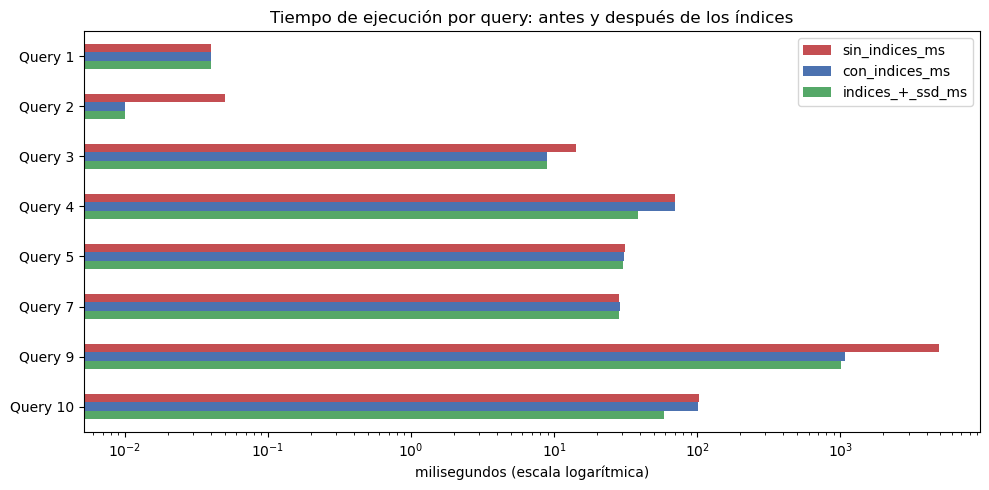

In [15]:
datos = ocho.drop(index='TOTAL 8 queries')[['sin_indices_ms', 'con_indices_ms', 'indices_+_ssd_ms']]
ax = datos.plot(kind='barh', figsize=(10, 5), color=['#C44E52', '#4C72B0', '#55A868'], logx=True)
ax.set_xlabel('milisegundos (escala logarítmica)')
ax.set_title('Tiempo de ejecución por query: antes y después de los índices')
ax.invert_yaxis(); plt.tight_layout(); plt.show()

### 2.4 Reescritura de la Query 9: corregir el fan-out también la hace más rápida

In [16]:
comparacion_9 = pd.DataFrame({
    'version': ['9 original (sin índices)', '9 original (con índices)', '9b corregida (con índices)'],
    'ms': [antes['Query 9'], despues['Query 9'], despues['Query 9b']]})
comparacion_9['veces_mas_rapida_que_original'] = (antes['Query 9'] / comparacion_9['ms']).round(1)
comparacion_9

,version,ms,veces_mas_rapida_que_original
0,9 original (sin índices),4912.25,1.0
1,9 original (con índices),1079.92,4.5
2,9b corregida (con índices),33.02,148.8


### 2.5 ¿Qué cambió en los planes de ejecución?
Las líneas clave del plan: **Seq Scan** = lee la tabla completa; **Index Scan / Index Only Scan** = va directo a las filas que necesita.

In [17]:
def lineas_clave(texto):
    claves = ('Scan', 'Join', 'Nested Loop', 'Execution Time', 'Rows Removed')
    return '\n'.join(l for l in texto.splitlines() if any(c in l for c in claves))

print('===== QUERY 4 - ANTES =====');  print(lineas_clave(plan_q4_antes))
print('\n===== QUERY 4 - CON ÍNDICES + SSD =====');  print(lineas_clave(plan_q4_ssd))

===== QUERY 4 - ANTES =====
              ->  Hash Join  (cost=416.53..12846.72 rows=32012 width=23) (actual time=23.098..41.997 rows=32562.00 loops=1)
                    ->  Hash Join  (cost=414.40..12753.45 rows=32012 width=18) (actual time=23.082..37.784 rows=32562.00 loops=1)
                          ->  Seq Scan on deliveries d  (cost=0.00..11289.00 rows=400000 width=14) (actual time=0.002..13.550 rows=400000.00 loops=1)
                                ->  Index Scan using idx_trips_departure on trips t  (cost=0.30..314.37 rows=8003 width=8) (actual time=0.010..1.044 rows=8155.00 loops=1)
                          ->  Seq Scan on routes r  (cost=0.00..1.50 rows=50 width=13) (actual time=0.005..0.008 rows=50.00 loops=1)
Execution Time: 70.681 ms

===== QUERY 4 - CON ÍNDICES + SSD =====
              ->  Nested Loop  (cost=2.84..7282.73 rows=32600 width=23) (actual time=0.027..11.755 rows=32562.00 loops=1)
                    ->  Hash Join  (cost=2.42..277.56 rows=8150 width=13) (

In [18]:
print('===== QUERY 9 - ANTES =====');  print(lineas_clave(plan_q9_antes))
print('\n===== QUERY 9 - DESPUÉS =====');  print(lineas_clave(plan_q9_despues))

===== QUERY 9 - ANTES =====
              ->  Subquery Scan on vehicle_metrics  (cost=450624.62..488127.71 rows=22 width=95) (actual time=3711.112..4851.318 rows=178.00 loops=1)
                          Rows Removed by Filter: 3
                                ->  Hash Join  (cost=220.53..31160.42 rows=2499925 width=45) (actual time=1.496..321.632 rows=3319510.00 loops=1)
                                      ->  Hash Left Join  (cost=2.12..2567.87 rows=99997 width=15) (actual time=0.019..28.158 rows=99998.00 loops=1)
                                            ->  Seq Scan on trips t  (cost=0.00..2281.00 rows=99997 width=12) (actual time=0.006..13.599 rows=99998.00 loops=1)
                                                  Rows Removed by Filter: 2
                                                  ->  Seq Scan on routes r  (cost=0.00..1.50 rows=50 width=11) (actual time=0.002..0.006 rows=50.00 loops=1)
                                            ->  Hash Right Join  (cost=6.50..155.9

In [19]:
uso = consulta('''
    SELECT relname AS tabla, indexrelname AS indice, idx_scan AS veces_usado,
           pg_size_pretty(pg_relation_size(indexrelid)) AS tamano
    FROM pg_stat_user_indexes
    WHERE indexrelname IN ('idx_deliveries_trip_id', 'idx_maintenance_vehicle_cost',
                           'idx_trips_vehicle_completed', 'idx_trips_status', 'idx_drivers_license_expiry')
    ORDER BY indice
''')
uso

,tabla,indice,veces_usado,tamano
0,deliveries,idx_deliveries_trip_id,57129,19 MB
1,drivers,idx_drivers_license_expiry,14,32 kB
2,maintenance,idx_maintenance_vehicle_cost,2745,216 kB
3,trips,idx_trips_status,14,704 kB
4,trips,idx_trips_vehicle_completed,7,3104 kB


In [20]:
# Guardar los resultados para la documentación
os.makedirs('../3. Documentación/img', exist_ok=True)
ocho.to_csv('../3. Documentación/tiempos_indices.csv')
ax = datos.plot(kind='barh', figsize=(10, 5), color=['#C44E52', '#4C72B0', '#55A868'], logx=True)
ax.set_xlabel('milisegundos (escala logarítmica)'); ax.set_title('Tiempo por query: antes y después de los índices')
ax.invert_yaxis(); plt.tight_layout(); plt.savefig('../3. Documentación/img/tiempos_indices.png', dpi=150); plt.close()
print('Guardado')

Guardado


## 3. Conclusiones del Avance 2

- Las 8 queries responden preguntas concretas del negocio: composición de flota, alertas de licencias, demanda por ciudad,
  carga por conductor, consumo por ruta, costo de mantenimiento y ranking para incentivos.
- Encontré y corregí un **error de lógica en la Query 9** (fan-out): la versión original inflaba kilómetros y costos.
  La versión corregida (9b) da números que cierran con la base y además es mucho más rápida.
- Con los **5 índices** el tiempo total de las 8 queries baja un **74,4%** (de 5.159 a 1.319 ms, ver la fila TOTAL de la tabla).
  La mayor ganancia está en la Query 9, que pasa a resolver los mantenimientos por vehículo directamente desde el índice.
- Con el ajuste para SSD (`random_page_cost = 1.1`, solo de sesión) PostgreSQL usa además el índice de entregas por viaje
  en las queries 4 y 10, que también bajan.
- **Las queries 5 y 7 no mejoran**, y es lo esperado: recorren los 100.000 viajes para agrupar, y para leer toda una tabla
  la lectura secuencial es la forma más rápida. Un índice solo ayuda cuando se necesita una parte chica de los datos.
- Los índices tienen costo (espacio y escrituras más lentas), por eso se crearon solo los que tienen una query que los usa.